In [3]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import sys
import os
from transformers import AutoModel, AutoTokenizer
import torch
import torch.nn as nn
from ast import literal_eval
from urllib import parse
import random
from tqdm import tqdm
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import UnivariateSpline

sys.path.append('..')

In [5]:
def fix_title(title):
    return parse.unquote(title).replace('_', ' ')

In [16]:
def get_all_scores(model, prediction_head, tokenizer, contexts, source_sections, target_title, target_lead, mentions):
    
    if target_title not in mentions:
        mentions[target_title] = ''
    
    scores = []
        
    for context, source_section in zip(contexts, source_sections):
        input = ["", ""]
        input[0] = f"{target_title} {mentions[target_title]}{tokenizer.sep_token}{target_lead}"
        input[1] = f"{source_section}{tokenizer.sep_token}{context}"
        input_tokens = tokenizer([input], return_tensors='pt', padding='max_length', truncation=True, max_length=512).to(device)
        embeddings = model(**input_tokens)['last_hidden_state'][:, 0, :]
        prediction_score = prediction_head(embeddings).squeeze().detach().cpu().numpy().item()
        scores.append((context,prediction_score))
    
    return scores

# Load model

In [17]:
device = 'cuda'

model = AutoModel.from_pretrained('/dlabdata1/tsoares/models/roberta_full_multilingual-all/model')
tokenizer = AutoTokenizer.from_pretrained('/dlabdata1/tsoares/models/roberta_full_multilingual-all/tokenizer')
prediction_head = nn.Sequential(nn.Linear(model.config.hidden_size, model.config.hidden_size),
                                nn.ReLU(),
                                nn.Linear(model.config.hidden_size, 1))
prediction_head.load_state_dict(torch.load('/dlabdata1/tsoares/models/roberta_full_multilingual-all/classification_head.pth', map_location='cpu'))

model = model.to(device)
prediction_head = prediction_head.to(device)

model = model.eval()
prediction_head = prediction_head.eval()

In [8]:
df = pd.read_parquet('test_data/en.parquet')
mentions = pd.read_parquet('test_data/en_mention_map.parquet')

In [10]:
df['target_title'] = df['target_title'].apply(fix_title)

In [14]:
mention_map_pre = mentions.to_dict('records')
mention_map = {}
for row in tqdm(mention_map_pre):
    title = fix_title(row['target_title'])
    if title in mention_map:
        mention_map[title].append(row['mention'])
    else:
        mention_map[title] = [row['mention']]

for title in tqdm(mention_map):
    mention_map[title] = list(set([mention.lower() for mention in mention_map[title]]))
    if len(mention_map[title]) > 10:
        mention_map[title].sort(key=lambda x: len(x))
        while len(mention_map[title]) > 10 and len(mention_map[title][0]) < 3:
            mention_map[title].pop(0)
        mention_map[title] = mention_map[title][:10]
        random.shuffle(mention_map[title])
    mention_map[title] = ' '.join(mention_map[title])

100%|██████████| 5938760/5938760 [00:17<00:00, 338699.76it/s]


## Compute scores

In [77]:
sample = df.sample(1)

target_title = sample['target_title'].values[0]
target_lead = sample['target_lead'].values[0]
first_version = sample['first_version'].values[0]

contexts = []
source_sections = []
contexts.append(sample['context'].values[0])
source_sections.append(sample['section'].values[0])
negative_contexts = literal_eval(sample['negative_contexts'].values[0])
for neg_context in negative_contexts:
    contexts.append(neg_context['context'])
    source_sections.append(neg_context['section'])

print('target_title', target_title)
print('target_lead', target_lead)
print('first_version', first_version)
print('contexts', contexts)
print('source_sections', source_sections)
print('number of candidates', len(contexts))

scores = get_all_scores(model, prediction_head, tokenizer, contexts, source_sections, target_title, target_lead, mention_map)

target_title Charles Leonard
target_lead Charles Frederick Leonard Jr. was an American pentathlete and a major general in the United States Army. Leonard won the silver medal in the 1936 Olympic Pentathlon. Charles Leonard's brother, William N. Leonard (1916–2005), was a World War II fighter ace. They were buried together in Arlington National Cemetery.
first_version 1165412756
contexts ['MG Frank H. Britton December 1960 – July 1961\nMG James K. Woolnough July 1961 – September 1962\nBG D.C. Clayman September 1962 – October 1962\nMG Clifton F. Von Kann October 1962 – June 1963\nBG Charles P. Brown June 1963 – August 1963\nMG Chas F. Leonard Jr. August 1963 – October 1964\nMG Hugh Exton October 1964 – June 1965\nMG Harry W. O. Kinnard July 1965 – May 1966\nMG John Norton May 1966 – March 1967\nMG John J. Tolson March 1967 – August 1968\nBG Richard L. Irby August 1968 – August 1968', 'This is a list of commanders of the US 1st Cavalry Division of the United States Army. \nMG Robert L. Ho

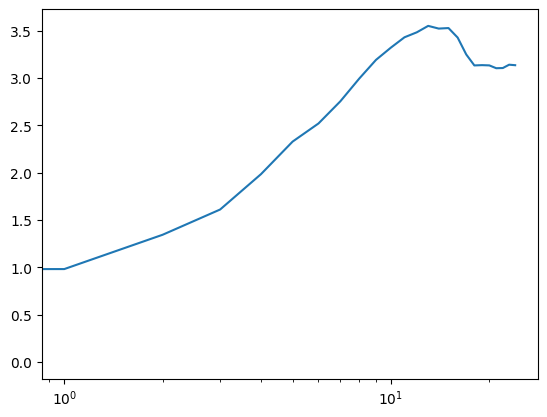

In [80]:
avg_diffs = []

for k in range(25):
    differences = [abs(just_scores[i+k] - just_scores[i]) for i in range(len(just_scores)-k)]

    # Compute the average of the absolute differences
    average_absolute_difference = sum(differences) / len(differences)

    avg_diffs.append(average_absolute_difference)

plt.plot(avg_diffs)
plt.xscale('log')

In [81]:
i = 300

print(contexts[i])
print(scores[i][1])
print("\n\n")

j = 301
print(contexts[j])
print(scores[j][1])

IndexError: list index out of range

In [1]:
raw_data_path = "/dlabdata1/tsoares/wikidumps/enwiki-NS0-20231101/raw_data"
processed_data_path = "/dlabdata1/tsoares/wikidumps/enwiki-NS0-20231101/processed_data"

In [19]:
goodlinks = pd.read_parquet("/dlabdata1/tsoares/wikidumps/enwiki-NS0-20231101/processed_data/good_links/good_links_170.parquet")

display(goodlinks)
print(goodlinks.columns)

,target_title,target_section,source_title,target_ID,target_QID,source_ID,source_QID,source_version,date_modified,mention,...,sentence_end_index,source_page_length,link_section_depth,context,context_sentence_start_index,context_sentence_end_index,context_mention_start_index,context_mention_end_index,context_span_start_index,context_span_end_index
0,Rowing_%28sport%29,Lead,Antun_Ivankovi%C4%87,25736,Q159354,58124117,Q47471391,https://en.wikipedia.org/w/index.php?title=Ant...,2023-05-24T22:43:06Z,rower,...,4860,18106,0.0.0,Antun Ivanković (born 25 March 1939) is a Croa...,0.0,57.0,51.0,56.0,0.0,130.0
1,Rowing_at_the_1960_Summer_Olympics_%E2%80%93_M...,Lead,Antun_Ivankovi%C4%87,52235189,Q22968930,58124117,Q47471391,https://en.wikipedia.org/w/index.php?title=Ant...,2023-05-24T22:43:06Z,men's coxless pair,...,5191,18106,0.0.0,Antun Ivanković (born 25 March 1939) is a Croa...,58.0,130.0,77.0,95.0,0.0,130.0
2,1960_Summer_Olympics,Lead,Antun_Ivankovi%C4%87,83243,Q8415,58124117,Q47471391,https://en.wikipedia.org/w/index.php?title=Ant...,2023-05-24T22:43:06Z,1960 Summer Olympics,...,5191,18106,0.0.0,Antun Ivanković (born 25 March 1939) is a Croa...,58.0,130.0,109.0,129.0,0.0,130.0
3,Moth,Lead,Beriotisia_typhlina,66633,Q1725788,24983719,Q4891869,https://en.wikipedia.org/w/index.php?title=Ber...,2021-01-08T05:14:03Z,moth,...,5725,17259,0.0.0,Beriotisia typhlina is a moth of the family No...,0.0,54.0,25.0,29.0,0.0,195.0
4,Noctuidae,Lead,Beriotisia_typhlina,293265,Q459180,24983719,Q4891869,https://en.wikipedia.org/w/index.php?title=Ber...,2021-01-08T05:14:03Z,Noctuidae,...,5725,17259,0.0.0,Beriotisia typhlina is a moth of the family No...,0.0,54.0,44.0,53.0,0.0,195.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
245487,Saint_John%2C_New_Brunswick,Lead,Embassy_of_Denmark%2C_Ottawa,28866,Q203403,12634628,Q5369665,https://en.wikipedia.org/w/index.php?title=Emb...,2021-10-29T16:01:26Z,Saint John,...,13965,45478,0.0.0,The Embassy of the Denmark in Ottawa (Danish: ...,239.0,407.0,351.0,361.0,106.0,407.0
245488,St._John%27s%2C_Newfoundland_and_Labrador,Lead,Embassy_of_Denmark%2C_Ottawa,70581,Q2082,12634628,Q5369665,https://en.wikipedia.org/w/index.php?title=Emb...,2021-10-29T16:01:26Z,St. John's,...,13965,45478,0.0.0,The Embassy of the Denmark in Ottawa (Danish: ...,239.0,407.0,363.0,373.0,106.0,407.0
245489,Toronto,Lead,Embassy_of_Denmark%2C_Ottawa,64646,Q172,12634628,Q5369665,https://en.wikipedia.org/w/index.php?title=Emb...,2021-10-29T16:01:26Z,Toronto,...,13965,45478,0.0.0,The Embassy of the Denmark in Ottawa (Danish: ...,239.0,407.0,375.0,382.0,0.0,407.0
245490,Vancouver,Lead,Embassy_of_Denmark%2C_Ottawa,32706,Q24639,12634628,Q5369665,https://en.wikipedia.org/w/index.php?title=Emb...,2021-10-29T16:01:26Z,Vancouver,...,13965,45478,0.0.0,The Embassy of the Denmark in Ottawa (Danish: ...,239.0,407.0,384.0,393.0,0.0,407.0


Index(['target_title', 'target_section', 'source_title', 'target_ID',
       'target_QID', 'source_ID', 'source_QID', 'source_version',
       'date_modified', 'mention', 'source_section', 'link_start_index',
       'link_end_index', 'sentence', 'sentence_raw', 'sentence_start_index',
       'sentence_end_index', 'source_page_length', 'link_section_depth',
       'context', 'context_sentence_start_index', 'context_sentence_end_index',
       'context_mention_start_index', 'context_mention_end_index',
       'context_span_start_index', 'context_span_end_index'],
      dtype='object')


In [20]:
goodpages = pd.read_parquet("/dlabdata1/tsoares/wikidumps/enwiki-NS0-20231101/processed_data/good_pages/good_pages_170.parquet")

display(goodpages)

print(goodpages.columns)

,title,ID,version,page_length,language,date_modified,lead_paragraph,QID
0,Emixustat,50000672,https://en.wikipedia.org/w/index.php?title=Emi...,81876,en,2023-04-05T23:49:51Z,Emixustat is a small molecule notable for its ...,Q25323930
1,Kim_Chan-mi_%28sport_shooter%29,38261045,https://en.wikipedia.org/w/index.php?title=Kim...,31358,en,2023-05-25T04:23:09Z,Kim Chan-mi is a South Korean sport shooter. S...,Q6408446
2,Georgios_Psyllas,46720858,https://en.wikipedia.org/w/index.php?title=Geo...,88221,en,2022-09-02T23:59:38Z,Georgios Psyllas was a Greek scholar and polit...,Q15981073
3,B%C4%83l%C8%9Bi_%28wine%29,17470741,https://en.wikipedia.org/w/index.php?title=B%C...,19313,en,2017-06-04T16:35:21Z,Bălți is a Moldovan wine region. This area has...,Q4852677
4,Santa_Loves_to_Boogie,67646146,https://en.wikipedia.org/w/index.php?title=San...,55125,en,2021-12-24T22:15:37Z,Santa Loves to Boogie is the 19th studio album...,Q106995210
...,...,...,...,...,...,...,...,...
9982,Thomas_Scott_%28archer%29,40916603,https://en.wikipedia.org/w/index.php?title=Tho...,34380,en,2023-05-22T10:04:43Z,Thomas Foster Scott was an American archer who...,Q16043801
9983,Shanghai_University_Law_School,11813930,https://en.wikipedia.org/w/index.php?title=Sha...,13575,en,2022-02-21T11:53:12Z,"Shanghai University Law School, operated by th...",Q7488524
9984,Jimmy_Miller_%28disambiguation%29,53454784,https://en.wikipedia.org/w/index.php?title=Jim...,5418,en,2023-01-14T18:38:00Z,Jimmy Miller (1942–1994) was an American recor...,Q30684673
9985,Jimmy_Merchant,56787494,https://en.wikipedia.org/w/index.php?title=Jim...,52032,en,2023-05-12T22:37:36Z,Jimmy Merchant is an American singer and music...,Q11978592


Index(['title', 'ID', 'version', 'page_length', 'language', 'date_modified',
       'lead_paragraph', 'QID'],
      dtype='object')


In [21]:
pages = pd.read_parquet("/dlabdata1/tsoares/wikidumps/enwiki-NS0-20231101/processed_data/pages/pages_170.parquet")

display(pages)
print(pages.columns)

,title,ID,version,page_length,language,date_modified,lead_paragraph,QID
0,Emixustat,50000672,https://en.wikipedia.org/w/index.php?title=Emi...,81876,en,2023-04-05T23:49:51Z,Emixustat is a small molecule notable for its ...,Q25323930
1,Kim_Chan-mi_%28sport_shooter%29,38261045,https://en.wikipedia.org/w/index.php?title=Kim...,31358,en,2023-05-25T04:23:09Z,Kim Chan-mi is a South Korean sport shooter. S...,Q6408446
2,Georgios_Psyllas,46720858,https://en.wikipedia.org/w/index.php?title=Geo...,88221,en,2022-09-02T23:59:38Z,Georgios Psyllas was a Greek scholar and polit...,Q15981073
3,B%C4%83l%C8%9Bi_%28wine%29,17470741,https://en.wikipedia.org/w/index.php?title=B%C...,19313,en,2017-06-04T16:35:21Z,Bălți is a Moldovan wine region. This area has...,Q4852677
4,Santa_Loves_to_Boogie,67646146,https://en.wikipedia.org/w/index.php?title=San...,55125,en,2021-12-24T22:15:37Z,Santa Loves to Boogie is the 19th studio album...,Q106995210
...,...,...,...,...,...,...,...,...
9995,Thomas_Scott_%28archer%29,40916603,https://en.wikipedia.org/w/index.php?title=Tho...,34380,en,2023-05-22T10:04:43Z,Thomas Foster Scott was an American archer who...,Q16043801
9996,Shanghai_University_Law_School,11813930,https://en.wikipedia.org/w/index.php?title=Sha...,13575,en,2022-02-21T11:53:12Z,"Shanghai University Law School, operated by th...",Q7488524
9997,Jimmy_Miller_%28disambiguation%29,53454784,https://en.wikipedia.org/w/index.php?title=Jim...,5418,en,2023-01-14T18:38:00Z,Jimmy Miller (1942–1994) was an American recor...,Q30684673
9998,Jimmy_Merchant,56787494,https://en.wikipedia.org/w/index.php?title=Jim...,52032,en,2023-05-12T22:37:36Z,Jimmy Merchant is an American singer and music...,Q11978592


Index(['title', 'ID', 'version', 'page_length', 'language', 'date_modified',
       'lead_paragraph', 'QID'],
      dtype='object')


In [10]:
simple_pages = pd.read_parquet("/dlabdata1/tsoares/wikidumps/enwiki-NS0-20231101/processed_data/simple_pages.parquet")

display(simple_pages)

,ID,QID
title,,
Anarchism,12,Q6199
Albedo,39,Q101038
A,290,Q9659
Alabama,303,Q173
Achilles,305,Q41746
...,...,...
SROSS-C2,75196950,None
Jonquil_Solt,75196958,Q123267416
Hellenistic_Arsenal%2C_Athens,75196965,None


In [13]:
redirect_map = pd.read_parquet("/dlabdata1/tsoares/wikidumps/enwiki-NS0-20231101/processed_data/redirect_map.parquet")

display(redirect_map)

,redirect
title,
AccessibleComputing,Computer_accessibility
AfghanistanHistory,History_of_Afghanistan
AfghanistanGeography,Geography_of_Afghanistan
AfghanistanPeople,Demographics_of_Afghanistan
AfghanistanCommunications,Communications_in_Afghanistan
...,...
Pro_Earth_Animal_Health_%28PEAH%29,Pro_Earth_Animal_Health
1897_world_fair,Brussels_International_Exposition_%281897%29
Jonquil_Frances_Loveday_Solt,Jonquil_Solt


In [22]:
redirect_map = pd.read_parquet("/dlabdata1/tsoares/wikidumps/enwiki-NS0-20231101/processed_data/redirect_map.parquet")

display(redirect_map)

,redirect
title,
AccessibleComputing,Computer_accessibility
AfghanistanHistory,History_of_Afghanistan
AfghanistanGeography,Geography_of_Afghanistan
AfghanistanPeople,Demographics_of_Afghanistan
AfghanistanCommunications,Communications_in_Afghanistan
...,...
Pro_Earth_Animal_Health_%28PEAH%29,Pro_Earth_Animal_Health
1897_world_fair,Brussels_International_Exposition_%281897%29
Jonquil_Frances_Loveday_Solt,Jonquil_Solt


In [16]:
links = pd.read_parquet("/dlabdata1/tsoares/wikidumps/enwiki-NS0-20231101/processed_data/links/links_170.parquet")

display(links)
print(links.columns)

,target_title,target_section,source_title,target_ID,target_QID,source_ID,source_QID,source_version,date_modified,mention,...,sentence_end_index,source_page_length,link_section_depth,context,context_sentence_start_index,context_sentence_end_index,context_mention_start_index,context_mention_end_index,context_span_start_index,context_span_end_index
0,Rowing_%28sport%29,Lead,Antun_Ivankovi%C4%87,25736,Q159354,58124117,Q47471391,https://en.wikipedia.org/w/index.php?title=Ant...,2023-05-24T22:43:06Z,rower,...,4860,18106,0.0.0,Antun Ivanković (born 25 March 1939) is a Croa...,0.0,57.0,51.0,56.0,0.0,130.0
1,Rowing_at_the_1960_Summer_Olympics_%E2%80%93_M...,Lead,Antun_Ivankovi%C4%87,52235189,Q22968930,58124117,Q47471391,https://en.wikipedia.org/w/index.php?title=Ant...,2023-05-24T22:43:06Z,men's coxless pair,...,5191,18106,0.0.0,Antun Ivanković (born 25 March 1939) is a Croa...,58.0,130.0,77.0,95.0,0.0,130.0
2,1960_Summer_Olympics,Lead,Antun_Ivankovi%C4%87,83243,Q8415,58124117,Q47471391,https://en.wikipedia.org/w/index.php?title=Ant...,2023-05-24T22:43:06Z,1960 Summer Olympics,...,5191,18106,0.0.0,Antun Ivanković (born 25 March 1939) is a Croa...,58.0,130.0,109.0,129.0,0.0,130.0
3,Moth,Lead,Beriotisia_typhlina,66633,Q1725788,24983719,Q4891869,https://en.wikipedia.org/w/index.php?title=Ber...,2021-01-08T05:14:03Z,moth,...,5725,17259,0.0.0,Beriotisia typhlina is a moth of the family No...,0.0,54.0,25.0,29.0,0.0,195.0
4,Noctuidae,Lead,Beriotisia_typhlina,293265,Q459180,24983719,Q4891869,https://en.wikipedia.org/w/index.php?title=Ber...,2021-01-08T05:14:03Z,Noctuidae,...,5725,17259,0.0.0,Beriotisia typhlina is a moth of the family No...,0.0,54.0,44.0,53.0,0.0,195.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
250011,Saint_John%2C_New_Brunswick,Lead,Embassy_of_Denmark%2C_Ottawa,28866,Q203403,12634628,Q5369665,https://en.wikipedia.org/w/index.php?title=Emb...,2021-10-29T16:01:26Z,Saint John,...,13965,45478,0.0.0,The Embassy of the Denmark in Ottawa (Danish: ...,239.0,407.0,351.0,361.0,106.0,407.0
250012,St._John%27s%2C_Newfoundland_and_Labrador,Lead,Embassy_of_Denmark%2C_Ottawa,70581,Q2082,12634628,Q5369665,https://en.wikipedia.org/w/index.php?title=Emb...,2021-10-29T16:01:26Z,St. John's,...,13965,45478,0.0.0,The Embassy of the Denmark in Ottawa (Danish: ...,239.0,407.0,363.0,373.0,106.0,407.0
250013,Toronto,Lead,Embassy_of_Denmark%2C_Ottawa,64646,Q172,12634628,Q5369665,https://en.wikipedia.org/w/index.php?title=Emb...,2021-10-29T16:01:26Z,Toronto,...,13965,45478,0.0.0,The Embassy of the Denmark in Ottawa (Danish: ...,239.0,407.0,375.0,382.0,0.0,407.0
250014,Vancouver,Lead,Embassy_of_Denmark%2C_Ottawa,32706,Q24639,12634628,Q5369665,https://en.wikipedia.org/w/index.php?title=Emb...,2021-10-29T16:01:26Z,Vancouver,...,13965,45478,0.0.0,The Embassy of the Denmark in Ottawa (Danish: ...,239.0,407.0,384.0,393.0,0.0,407.0


Index(['target_title', 'target_section', 'source_title', 'target_ID',
       'target_QID', 'source_ID', 'source_QID', 'source_version',
       'date_modified', 'mention', 'source_section', 'link_start_index',
       'link_end_index', 'sentence', 'sentence_raw', 'sentence_start_index',
       'sentence_end_index', 'source_page_length', 'link_section_depth',
       'context', 'context_sentence_start_index', 'context_sentence_end_index',
       'context_mention_start_index', 'context_mention_end_index',
       'context_span_start_index', 'context_span_end_index'],
      dtype='object')


In [18]:
sections = pd.read_parquet("/dlabdata1/tsoares/wikidumps/enwiki-NS0-20231101/processed_data/sections/sections_170.parquet")

display(sections)
print(sections.columns)

,section,text,depth,title,links
0,Lead,Antun Ivanković (born 25 March 1939) is a Cro...,0,Antun_Ivankovi%C4%87,"[{'mention': 'rower', 'target_title': 'Rowing_..."
1,References,References\n,1,Antun_Ivankovi%C4%87,[]
2,Lead,\n \n \nBeriotisia typhlina is a moth of the ...,0,Beriotisia_typhlina,"[{'mention': 'moth', 'target_title': 'Moth'}, ..."
3,External links,External links\n,1,Beriotisia_typhlina,[]
4,Lead,\n \nBembidion rufinum is a species of ground...,0,Bembidion_rufinum,"[{'mention': 'ground beetle', 'target_title': ..."
...,...,...,...,...,...
60758,Geography,Geography\nShichenga is located 3 km east of S...,1,Shichenga,"[{'mention': 'Shuyskoye', 'target_title': 'Shu..."
60759,References,References\n,2,Shichenga,[]
60760,Lead,Sajjad Hussain may refer to: Sajjad Hussain (c...,0,Sajjad_Hussain,[]
60761,Lead,The Embassy of the Denmark in Ottawa (Danish: ...,0,Embassy_of_Denmark%2C_Ottawa,"[{'mention': 'Ottawa', 'target_title': 'Ottawa..."


Index(['section', 'text', 'depth', 'title', 'links'], dtype='object')


In [28]:
test_data = pd.read_parquet("/dlabdata1/tsoares/wikidumps/enwiki-NS0-20231001/eval/test_data.parquet")

In [29]:
display(test_data)

,source_title,source_ID,target_title,context,section,mention_present,source_lead,first_version,second_version,direct_match,missing_category,negative_contexts
0,Ed_Wood,10520,Sam_Singer,List of films considered the worst\nB movie\nZ...,See also,False,"American screenwriter, director, producer, act...",1178200261,1178634913,False,missing_sentence,"[{'context': ""American screenwriter, director,..."
1,Association_football,10568,FIEFF,The FA ban led to the formation of the short-l...,History,False,"Team sport played with a spherical ball\n""Socc...",1181148816,1181286939,False,missing_span,[{'context': 'Team sport played with a spheric...
2,Association_football,10568,1970_Women%27s_World_Cup,The FA ban led to the formation of the short-l...,History,False,"Team sport played with a spherical ball\n""Socc...",1181148816,1181286939,False,missing_span,[{'context': 'Team sport played with a spheric...
3,Association_football,10568,1971_Women%27s_World_Cup,The FA ban led to the formation of the short-l...,History,False,"Team sport played with a spherical ball\n""Socc...",1181148816,1181286939,False,missing_span,[{'context': 'Team sport played with a spheric...
4,Francis_Ford_Coppola,10576,Francis_Ford_Coppola%27s_unrealized_projects,See also \nFilm portal\nUnited States portal\n...,See also,False,American filmmaker\nFrancis Ford Coppola (/ˈko...,1177938512,1179216333,False,missing_mention,"[{'context': ""American filmmaker\n\n\nFrancis ..."
...,...,...,...,...,...,...,...,...,...,...,...,...
415824,Himalaya_Wellness_Company,31176877,Twitter,"Controversies In September 2023, Himalaya Well...",Controversies,True,Indian multinational pharmaceutical company\nH...,1177600639,1177603556,True,None,[]
415825,Himalaya_Wellness_Company,31176877,Twitter,Products Himalaya Herbal Healthcare has a very...,Products,False,Indian multinational pharmaceutical company\nH...,1176581185,1177600421,False,missing_section,[]
415826,Himalaya_Wellness_Company,31176877,Twitter,Products Himalaya Herbal Healthcare has a very...,Products,False,Indian multinational pharmaceutical company\nH...,1176581185,1177600421,False,missing_section,[]
415827,Himalaya_Wellness_Company,31176877,Twitter,Products Himalaya Herbal Healthcare has a very...,Products,False,Indian multinational pharmaceutical company\nH...,1176581185,1177600421,False,missing_section,[]
